langkah langkah 

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import pearsonr, jarque_bera
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_curve, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report,  f1_score,  roc_auc_score
from sklearn.model_selection import cross_val_score
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
data = pd.read_csv("heart.csv")
data.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
data.shape

(1025, 14)

In [4]:
data.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [5]:
data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [7]:
data.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

In [8]:
# category = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
# data[category] = data[category].astype('object')
# data.dtypes

In [9]:
data['sex'] = data['sex'].replace({1: 'Male',
                                   0: 'Female'})
data['cp'] = data['cp'].replace({0: 'typical angina',
                                 1: 'atypical angina',
                                 2: 'non-anginal pain',
                                 3: 'asymptomatic'})
data['fbs'] = data['fbs'].replace({0: 'No',
                                   1: 'Yes'})
data['restecg'] = data['restecg'].replace({0: 'probable or definite left ventricular hypertrophy',
                                           1:'normal',
                                           2: 'ST-T Wave abnormal'})
data['exang'] = data['exang'].replace({0: 'No',
                                       1: 'Yes'})
data['slope'] = data['slope'].replace({0: 'downsloping',
                                       1: 'flat',
                                       2: 'upsloping'})
data['thal'] = data['thal'].replace({1: 'normal',
                                     2: 'fixed defect',
                                     3: 'reversable defect'})
data['ca'] = data['ca'].replace({0: 'Number of major vessels: 0',
                                 1: 'Number of major vessels: 1',
                                 2: 'Number of major vessels: 2',
                                 3: 'Number of major vessels: 3'})
data['target'] = data['target'].replace({0: 'No disease',
                                         1: 'Disease'})

In [10]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   object 
 2   cp        1025 non-null   object 
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   object 
 6   restecg   1025 non-null   object 
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   object 
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   object 
 11  ca        1025 non-null   object 
 12  thal      1025 non-null   object 
 13  target    1025 non-null   object 
dtypes: float64(1), int64(4), object(9)
memory usage: 112.2+ KB


In [11]:
data['thal'].value_counts()

thal
fixed defect         544
reversable defect    410
normal                64
0                      7
Name: count, dtype: int64

In [12]:
numerical_col = data.select_dtypes(include=['int64', 'float64'])
categorical_col = data.select_dtypes(include=['object'])

In [13]:
for col in categorical_col:
    print(f"Nilai Data dalam {col}: {data[col].unique()}")

Nilai Data dalam sex: ['Male' 'Female']
Nilai Data dalam cp: ['typical angina' 'atypical angina' 'non-anginal pain' 'asymptomatic']
Nilai Data dalam fbs: ['No' 'Yes']
Nilai Data dalam restecg: ['normal' 'probable or definite left ventricular hypertrophy'
 'ST-T Wave abnormal']
Nilai Data dalam exang: ['No' 'Yes']
Nilai Data dalam slope: ['upsloping' 'downsloping' 'flat']
Nilai Data dalam ca: ['Number of major vessels: 2' 'Number of major vessels: 0'
 'Number of major vessels: 1' 'Number of major vessels: 3' 4]
Nilai Data dalam thal: ['reversable defect' 'fixed defect' 'normal' 0]
Nilai Data dalam target: ['No disease' 'Disease']


In [14]:
data['ca'].value_counts()

ca
Number of major vessels: 0    578
Number of major vessels: 1    226
Number of major vessels: 2    134
Number of major vessels: 3     69
4                              18
Name: count, dtype: int64

In [15]:
data[data['ca'] == 4]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
52,38,Male,non-anginal pain,138,175,No,normal,173,No,0.0,upsloping,4,fixed defect,Disease
83,38,Male,non-anginal pain,138,175,No,normal,173,No,0.0,upsloping,4,fixed defect,Disease
128,52,Male,non-anginal pain,138,223,No,normal,169,No,0.0,upsloping,4,fixed defect,Disease
208,38,Male,non-anginal pain,138,175,No,normal,173,No,0.0,upsloping,4,fixed defect,Disease
242,38,Male,non-anginal pain,138,175,No,normal,173,No,0.0,upsloping,4,fixed defect,Disease
290,52,Male,non-anginal pain,138,223,No,normal,169,No,0.0,upsloping,4,fixed defect,Disease
340,38,Male,non-anginal pain,138,175,No,normal,173,No,0.0,upsloping,4,fixed defect,Disease
348,43,Male,typical angina,132,247,Yes,probable or definite left ventricular hypertrophy,143,Yes,0.1,flat,4,reversable defect,No disease
417,52,Male,non-anginal pain,138,223,No,normal,169,No,0.0,upsloping,4,fixed defect,Disease
428,43,Male,typical angina,132,247,Yes,probable or definite left ventricular hypertrophy,143,Yes,0.1,flat,4,reversable defect,No disease


In [16]:
data['thal'].value_counts()

thal
fixed defect         544
reversable defect    410
normal                64
0                      7
Name: count, dtype: int64

In [17]:
data[data['thal'] == 0]

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
14,52,Male,typical angina,128,204,Yes,normal,156,Yes,1.0,flat,Number of major vessels: 0,0,No disease
319,53,Female,non-anginal pain,128,216,No,probable or definite left ventricular hypertrophy,115,No,0.0,upsloping,Number of major vessels: 0,0,Disease
329,53,Female,non-anginal pain,128,216,No,probable or definite left ventricular hypertrophy,115,No,0.0,upsloping,Number of major vessels: 0,0,Disease
359,53,Female,non-anginal pain,128,216,No,probable or definite left ventricular hypertrophy,115,No,0.0,upsloping,Number of major vessels: 0,0,Disease
686,52,Male,typical angina,128,204,Yes,normal,156,Yes,1.0,flat,Number of major vessels: 0,0,No disease
734,52,Male,typical angina,128,204,Yes,normal,156,Yes,1.0,flat,Number of major vessels: 0,0,No disease
893,52,Male,typical angina,128,204,Yes,normal,156,Yes,1.0,flat,Number of major vessels: 0,0,No disease


In [18]:
data.loc[data['ca']==4, 'ca'] = np.nan
data.loc[data['thal']==0, 'thal'] = np.nan

In [19]:
data['ca'].value_counts()

ca
Number of major vessels: 0    578
Number of major vessels: 1    226
Number of major vessels: 2    134
Number of major vessels: 3     69
Name: count, dtype: int64

In [20]:
data['thal'].value_counts()

thal
fixed defect         544
reversable defect    410
normal                64
Name: count, dtype: int64

In [21]:
print('total missing value:\n', data.isna().sum())

total missing value:
 age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca          18
thal         7
target       0
dtype: int64


In [22]:
modus_ca = data['ca'].mode()[0]
data['ca'] = data['ca'].fillna(modus_ca)

modus_thal = data['thal'].mode()[0]
data['thal'] = data['thal'].fillna(modus_thal)

In [23]:
print('Total missing value:\n', data.isna().sum())

Total missing value:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [ ]:
# Memeriksa data duplikat
print('total duplicate data:', data.duplicated().sum())

total duplicate data: 723


In [ ]:
# Hapus data duplikat
data.drop_duplicates(keep='first', inplace=True)
print('total duplicate data:', data.duplicated().sum())

total duplicate data: 0


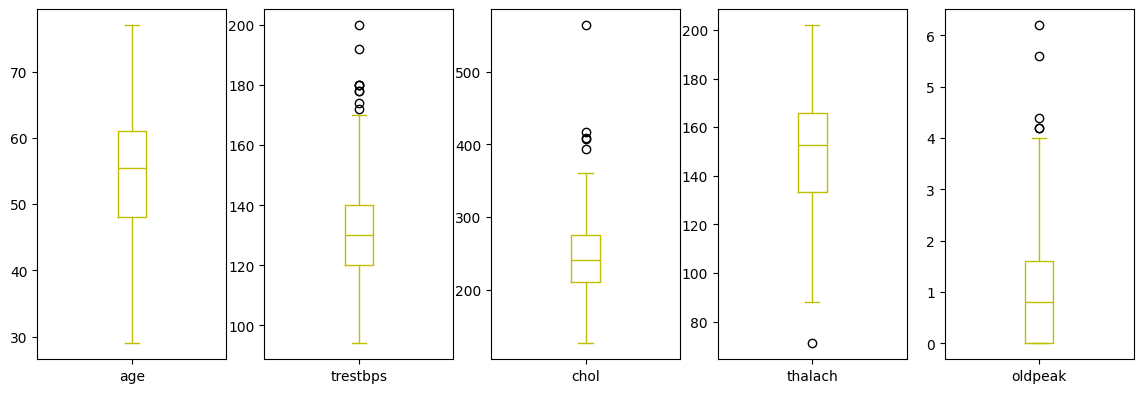

In [26]:
data.plot(kind = 'box', subplots = True, layout = (2,7), sharex = False, sharey = False, figsize = (20, 10), color = 'y')
plt.show()

In [27]:
#Mencari tahu data yang outliers dengan mendefinisikan fungsi
continous_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']  
def outliers(data_out, drop = False):
    for each_feature in data_out.columns:
        feature_data = data_out[each_feature]
        Q1 = np.percentile(feature_data, 25.) 
        Q3 = np.percentile(feature_data, 75.) 
        IQR = Q3-Q1 
        outlier_step = IQR * 1.5 
        outliers = feature_data[~((feature_data >= Q1 - outlier_step) & (feature_data <= Q3 + outlier_step))].index.tolist()  
        if not drop:
            print('For the feature {}, Num of Outliers is {}'.format(each_feature, len(outliers)))
        if drop:
            data.drop(outliers, inplace = True, errors = 'ignore')
            print('Outliers from {} feature removed'.format(each_feature))

outliers(data[continous_features])

For the feature age, Num of Outliers is 0
For the feature trestbps, Num of Outliers is 9
For the feature chol, Num of Outliers is 5
For the feature thalach, Num of Outliers is 1
For the feature oldpeak, Num of Outliers is 5


In [28]:
# Menghapus outlier dengan fungsi sebelumnya
outliers(data[continous_features], drop = True)

Outliers from age feature removed
Outliers from trestbps feature removed
Outliers from chol feature removed
Outliers from thalach feature removed
Outliers from oldpeak feature removed


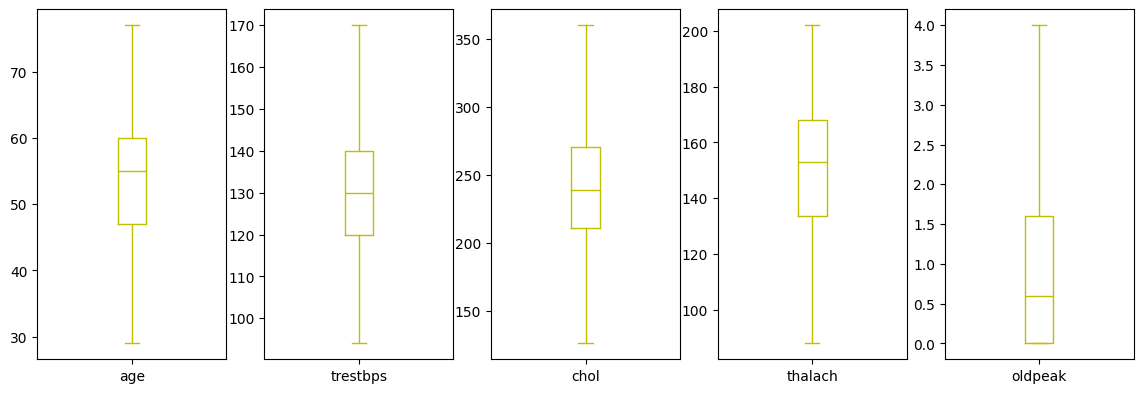

In [29]:
data.plot(kind = 'box', subplots = True, layout = (2,7), sharex = False, sharey = False, figsize = (20, 10), color = 'y')
plt.show()

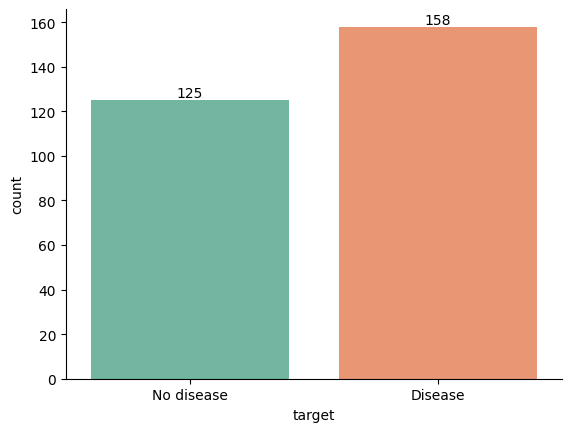

In [30]:
# Memeriksa data imbalance
ax = sns.countplot(data= data, x='target', palette='Set2')
for label in ax.containers:
    ax.bar_label(label)
sns.despine()
plt.show()

In [31]:
# Melihat statistik deskriptif dari data
data.describe()

,age,trestbps,chol,thalach,oldpeak
count,283.000000,283.000000,283.000000,283.000000,283.000000
mean,54.049470,129.883392,242.314488,149.961131,0.951943
std,9.128186,15.387795,44.654188,22.691625,1.026400
min,29.000000,94.000000,126.000000,88.000000,0.000000
25%,47.000000,120.000000,210.500000,133.500000,0.000000
50%,55.000000,130.000000,239.000000,153.000000,0.600000
75%,60.000000,140.000000,270.500000,168.000000,1.600000
max,77.000000,170.000000,360.000000,202.000000,4.000000



--- Visualisasi EDA ---


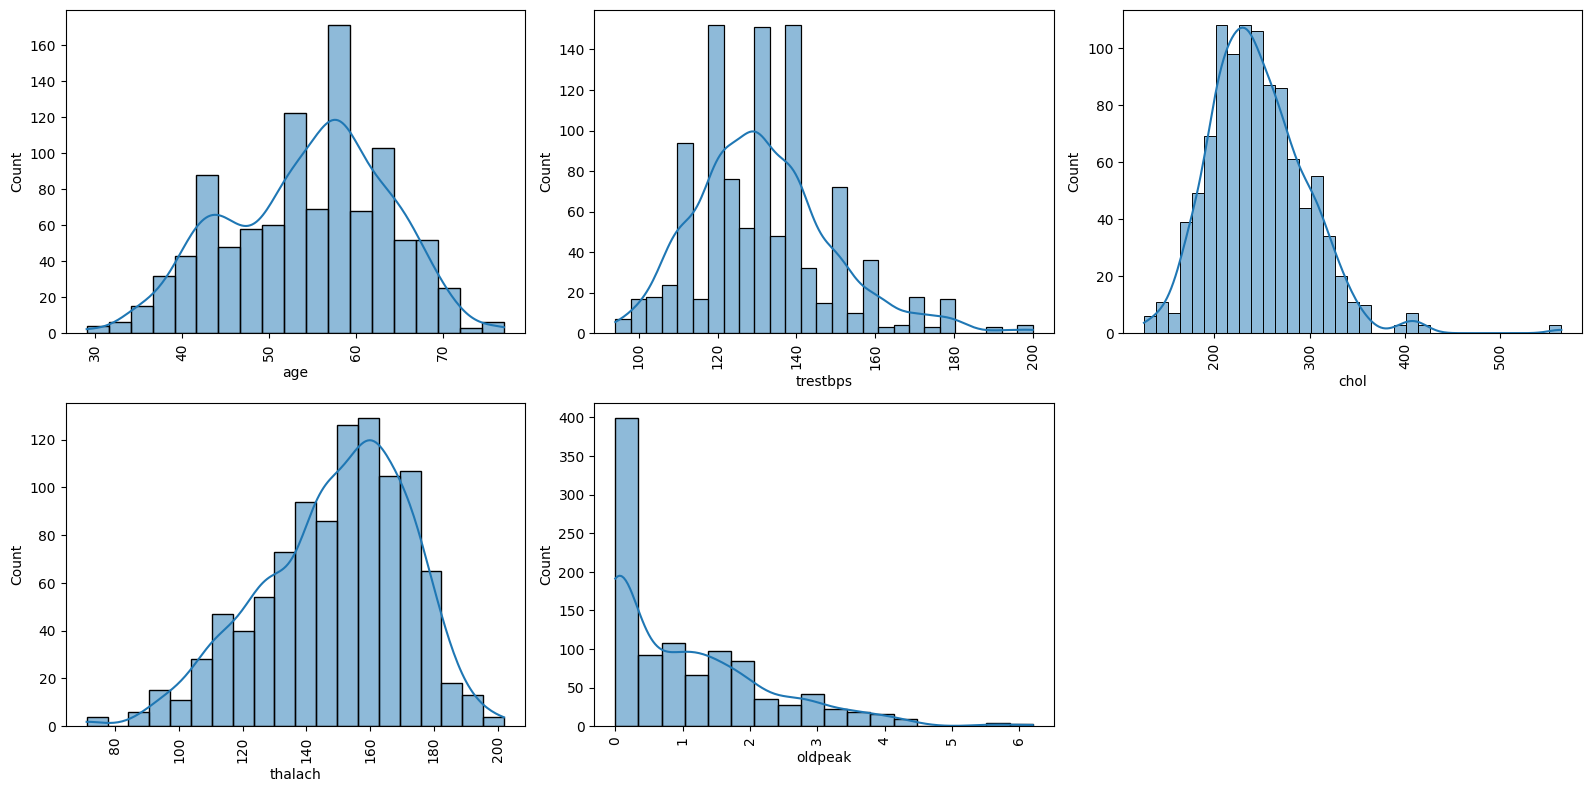

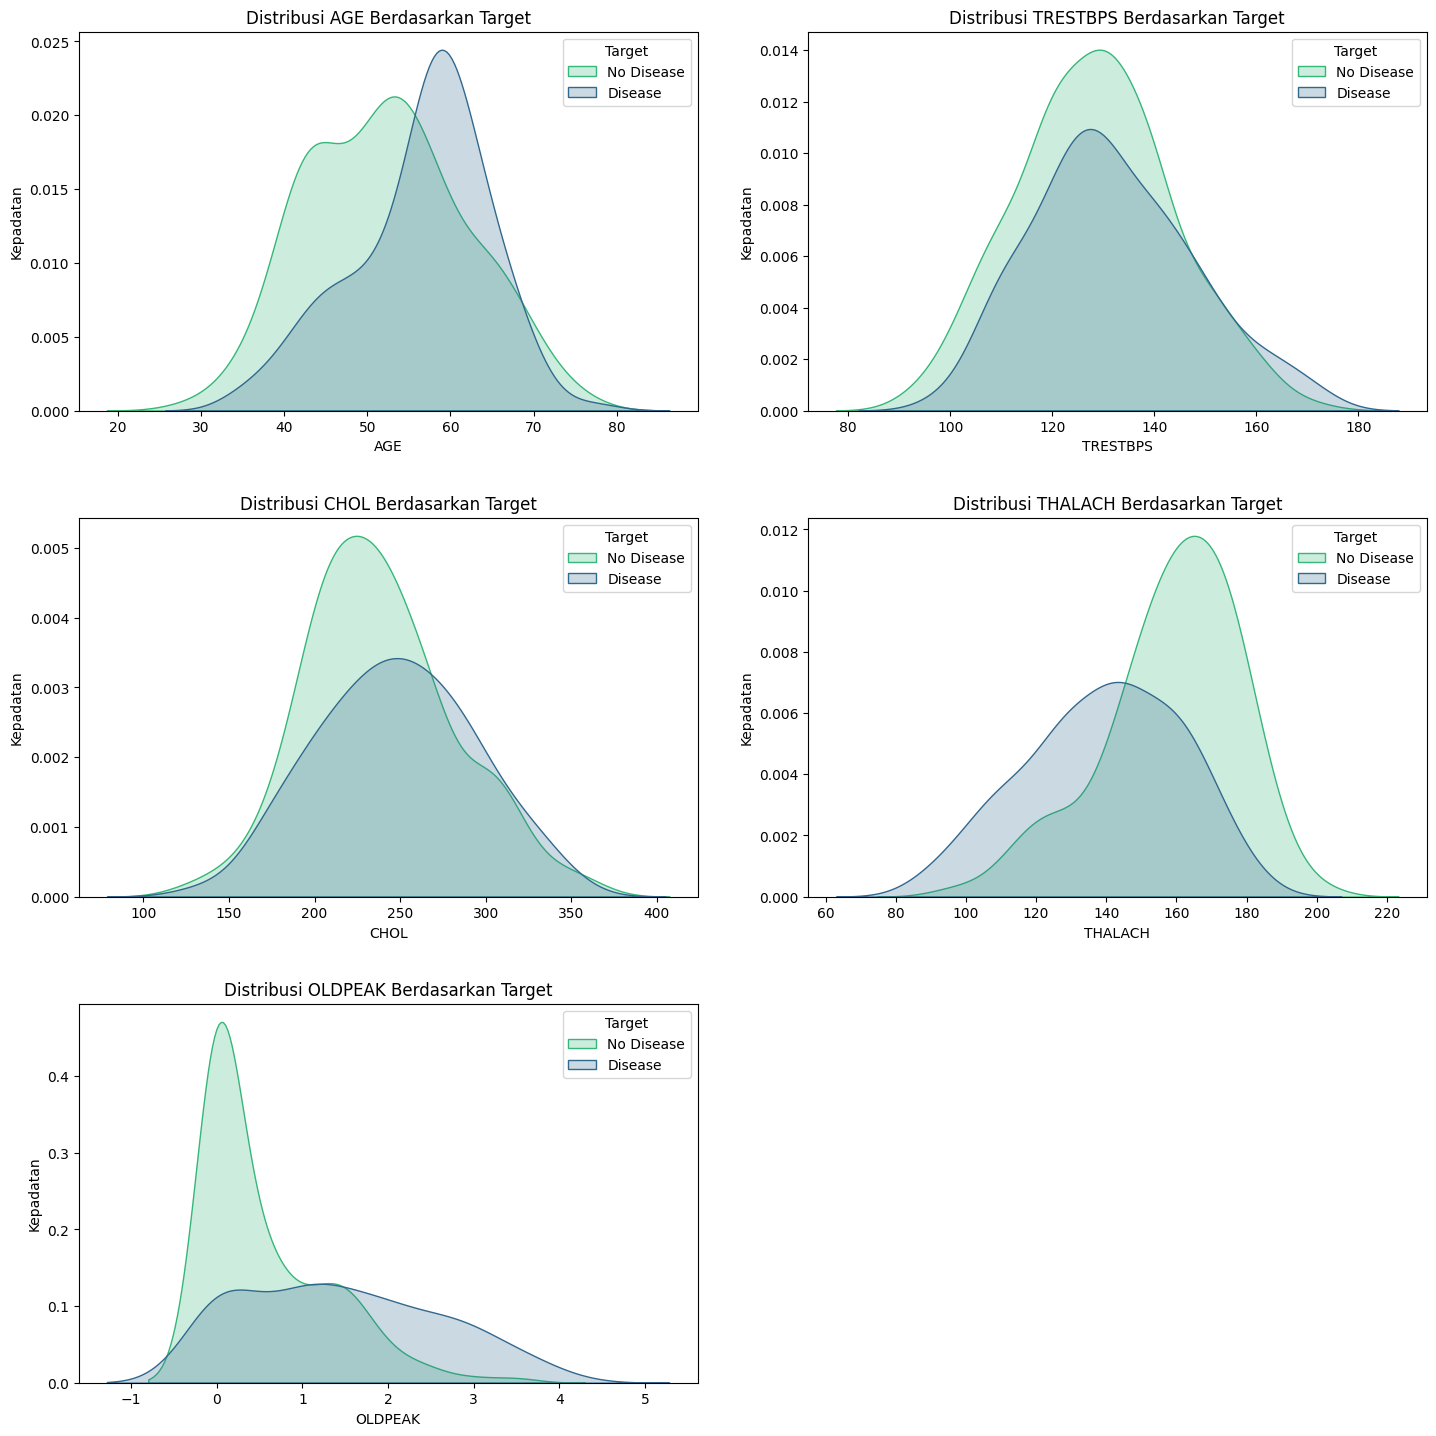

In [32]:
print("\n--- Visualisasi EDA ---")

# 1.1 Memvisualisasikan distribusi variabel numerical
plt.figure(figsize=(16,8))
for index,column in enumerate(numerical_col):
    plt.subplot(2,3,index+1)
    sns.histplot(data=numerical_col,x=column,kde=True)
    plt.xticks(rotation = 90)
plt.tight_layout(pad = 1.0)
plt.show()

# 1.2 Density Plot untuk Fitur Numerik Berdasarkan Target
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 15))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.kdeplot(data=data, x=col, hue='target', fill=True, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Distribusi {col.upper()} Berdasarkan Target', fontsize=12)
    axes[i].set_xlabel(col.upper(), fontsize=10)
    axes[i].set_ylabel('Kepadatan', fontsize=10)
    axes[i].legend(title='Target', labels=['No Disease', 'Disease'])

if len(numerical_cols) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout(pad=3.0)
plt.show()

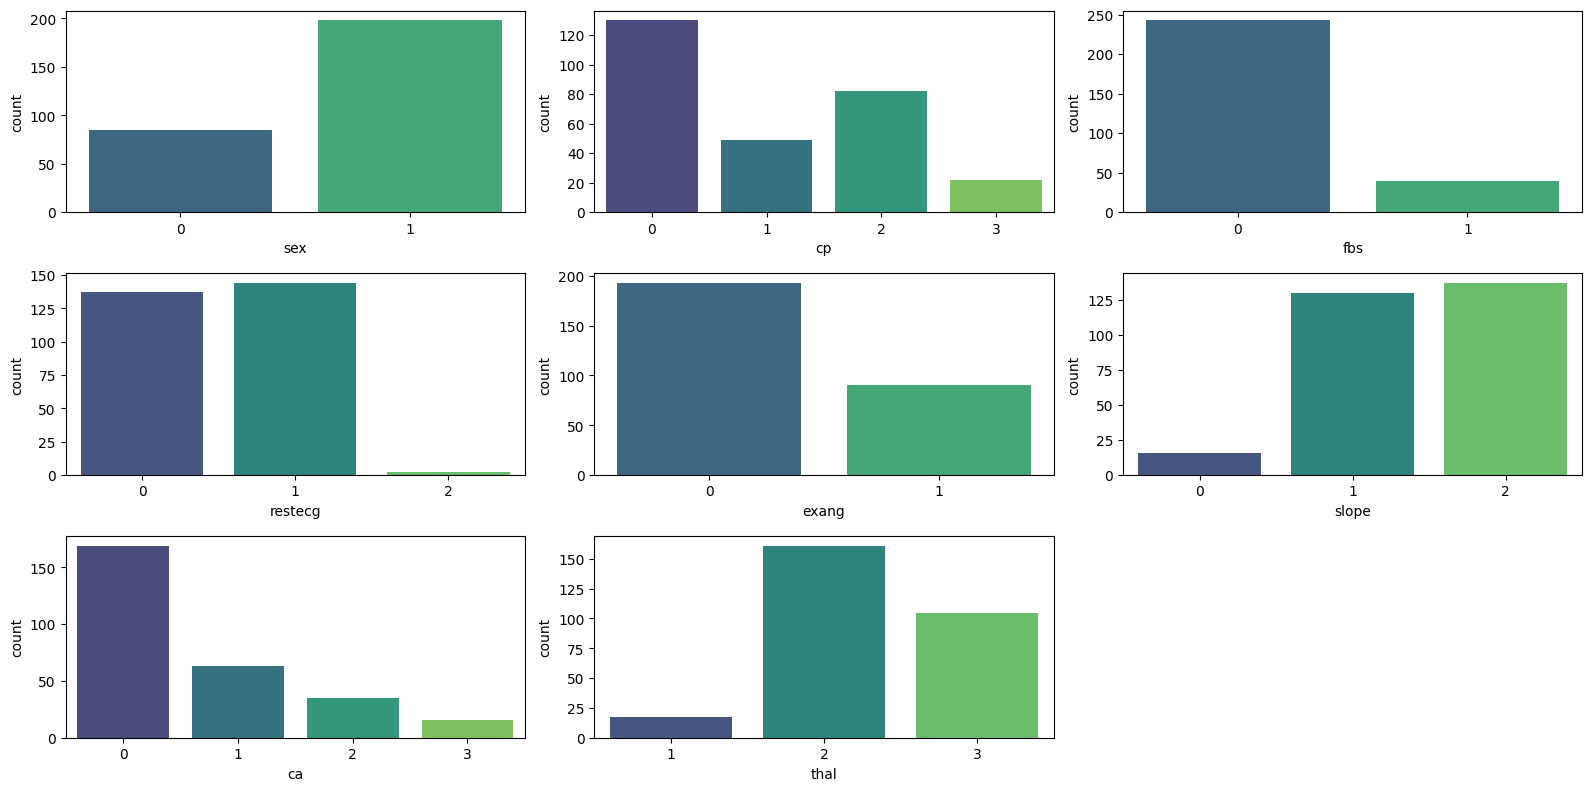

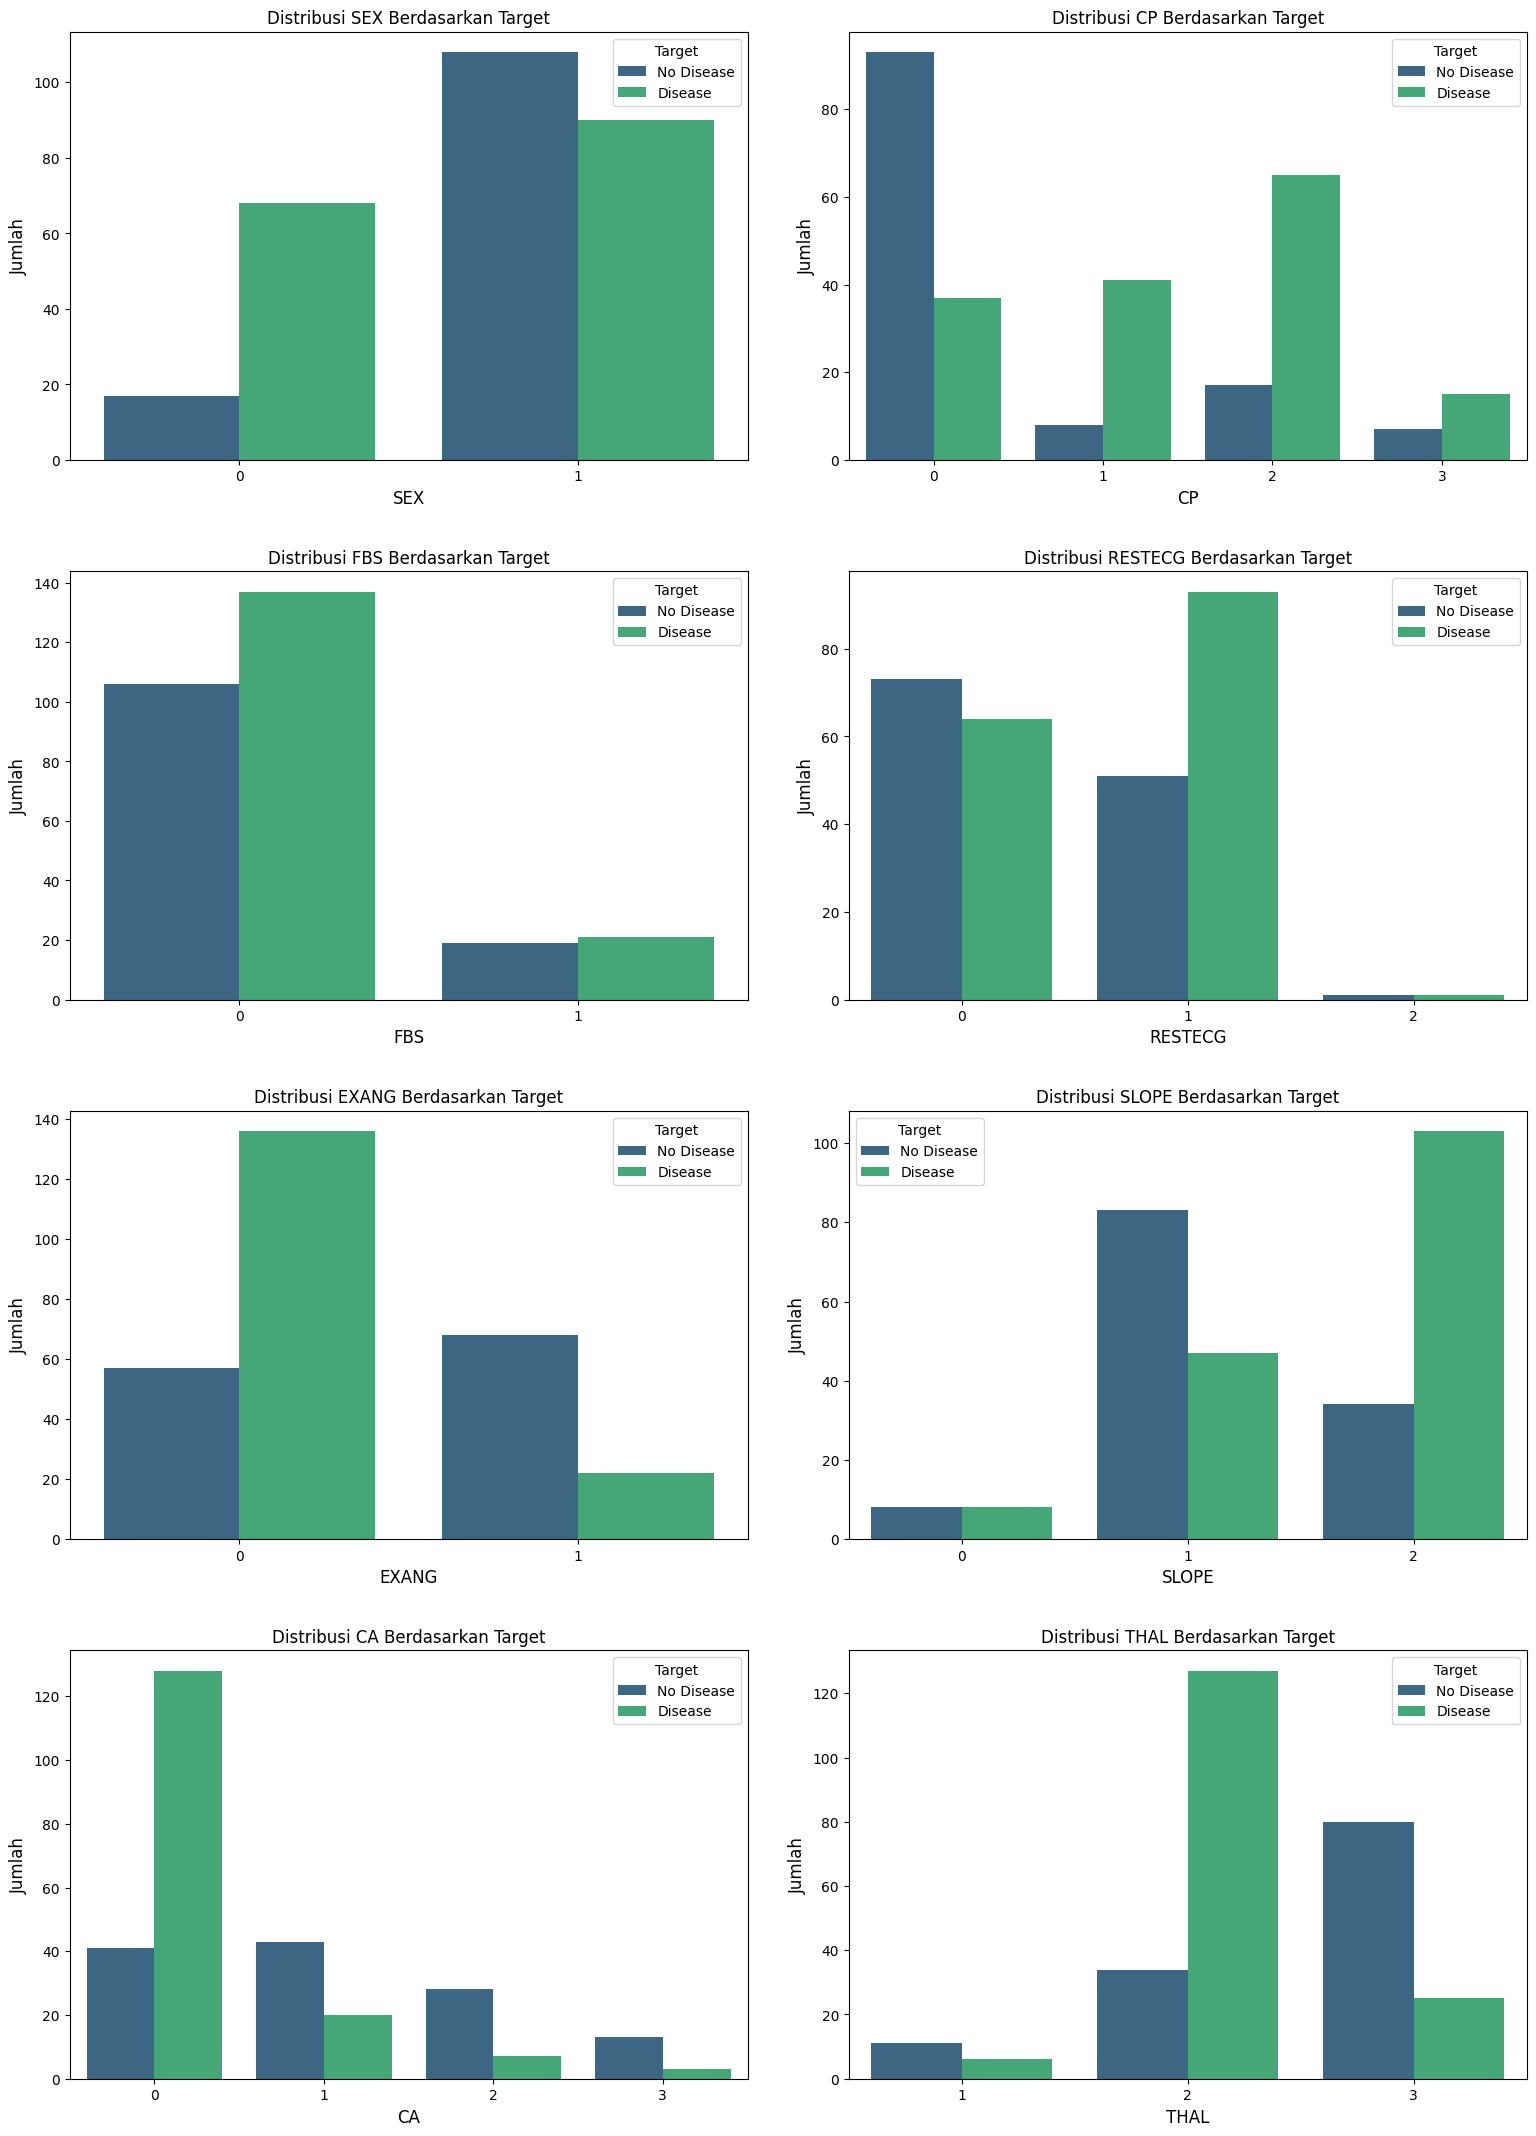

In [33]:
# Buat salinan data agar data asli tidak berubah
data_copy = data.copy()

mapping_dict = {
    'sex': {'Male': 1, 'Female': 0},
    'cp': {'typical angina': 0, 'atypical angina': 1, 'non-anginal pain': 2, 'asymptomatic': 3},
    'fbs': {'Yes': 1, 'No': 0},
    'restecg': {'normal': 1, 'probable or definite left ventricular hypertrophy': 0, 'ST-T Wave abnormal': 2},
    'exang': {'Yes': 1, 'No': 0},
    'slope': {'upsloping': 2, 'flat': 1, 'downsloping': 0},
    'ca': {'Number of major vessels: 0': 0, 'Number of major vessels: 1': 1, 'Number of major vessels: 2': 2, 'Number of major vessels: 3': 3, 'Number of major vessels: 4': 4},
    'thal': {'normal': 1, 'reversable defect': 3, 'fixed defect': 2}
}

# Lakukan konversi pada salinan data
for col, mapping in mapping_dict.items():
    if col in data_copy.columns:
        data_copy[col] = data_copy[col].map(mapping)

# 2.1 Memvisualisasikan distribusi variabel categorical
plt.figure(figsize=(16, 8))
categorical_cols_to_plot = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

for index, column in enumerate(categorical_cols_to_plot):
    plt.subplot(3, 3, index + 1)
    # Gunakan data_copy yang sudah di konversi
    sns.countplot(data=data_copy, x=column, palette='viridis')
    plt.xticks(rotation=0)
plt.tight_layout(pad=1.0)
plt.show()

# 2.2 Grouped Bar Charts untuk Fitur Kategorikal Berdasarkan Target
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 22))
axes = axes.flatten()

for i, col in enumerate(categorical_cols_to_plot):
    # Gunakan data_copy yang sudah dikonversi
    # Biarkan hue='target' karena 'target' belum dikonversi
    sns.countplot(data=data_copy, x=col, hue='target', ax=axes[i], palette='viridis')
    axes[i].set_title(f'Distribusi {col.upper()} Berdasarkan Target', fontsize=12)
    axes[i].set_xlabel(col.upper(), fontsize=12)
    axes[i].set_ylabel('Jumlah', fontsize=12)
    axes[i].legend(title='Target', labels=['No Disease', 'Disease'])
    axes[i].tick_params(axis='x', rotation=0)

if len(categorical_cols_to_plot) < len(axes):
    for j in range(len(categorical_cols_to_plot), len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout(pad=3.0)
plt.show()




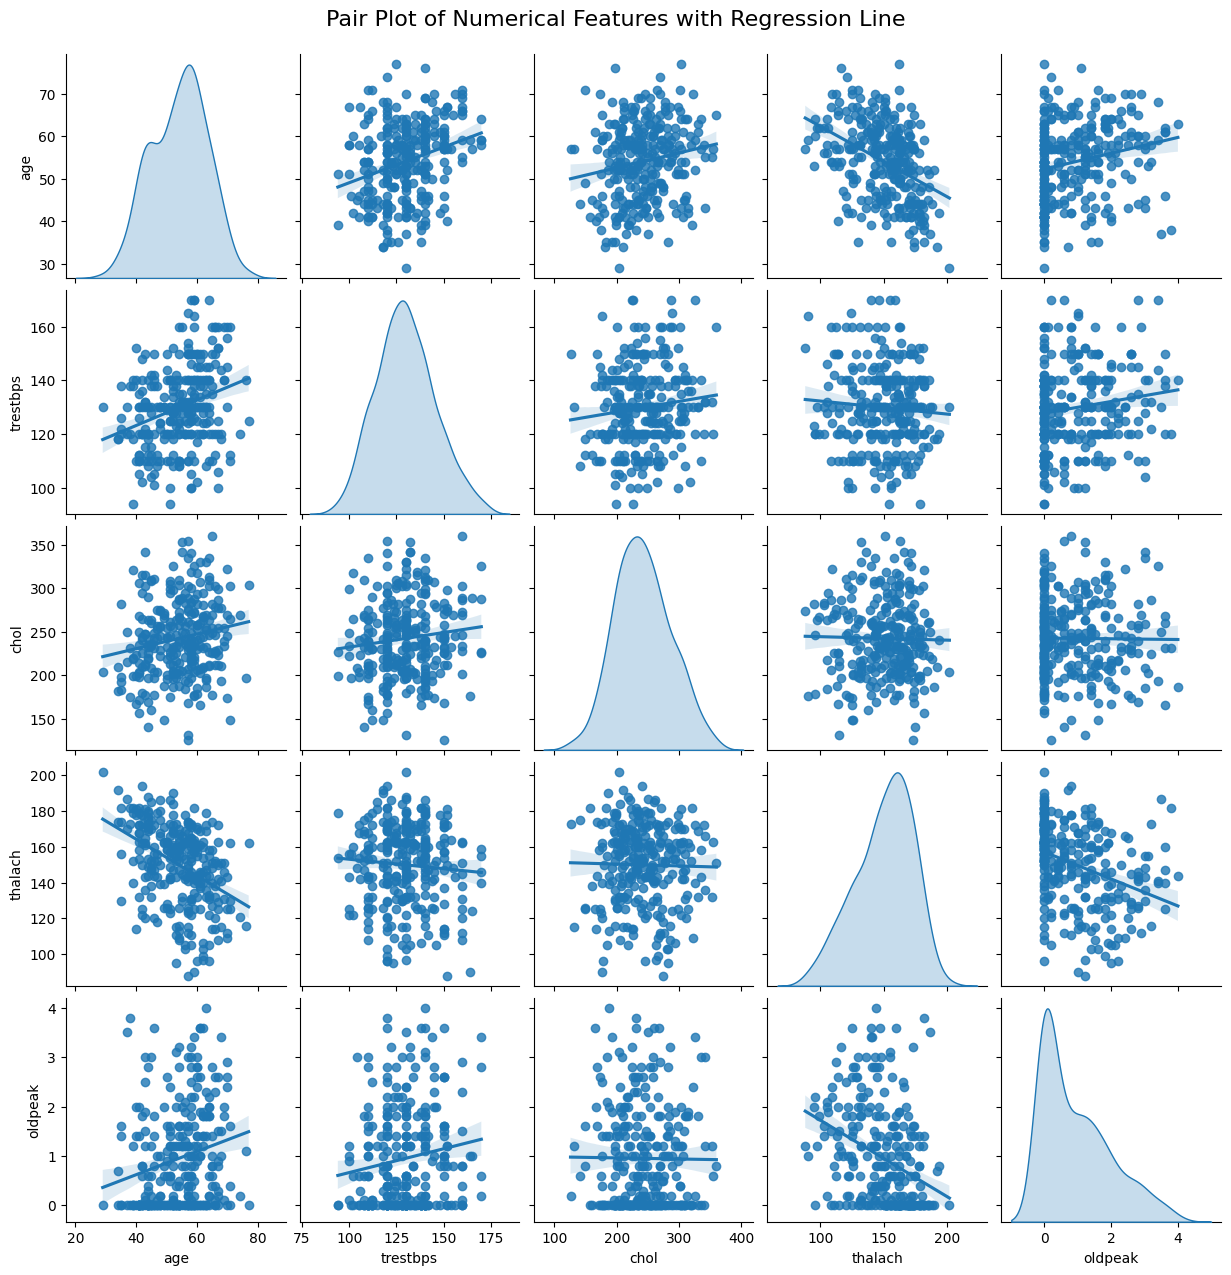

In [34]:
# 3. Pair Plot dengan Garis Regresi
df_numeric = data.copy()

# Tambahkan kind='reg' untuk menampilkan garis regresi pada plot
sns.pairplot(df_numeric, diag_kind='kde', kind='reg')

# Judul juga bisa disesuaikan untuk mencerminkan adanya garis regresi
plt.suptitle('Pair Plot of Numerical Features with Regression Line', y=1.02, fontsize=16)
plt.show()

In [35]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 283 entries, 0 to 878
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       283 non-null    int64  
 1   sex       283 non-null    object 
 2   cp        283 non-null    object 
 3   trestbps  283 non-null    int64  
 4   chol      283 non-null    int64  
 5   fbs       283 non-null    object 
 6   restecg   283 non-null    object 
 7   thalach   283 non-null    int64  
 8   exang     283 non-null    object 
 9   oldpeak   283 non-null    float64
 10  slope     283 non-null    object 
 11  ca        283 non-null    object 
 12  thal      283 non-null    object 
 13  target    283 non-null    object 
dtypes: float64(1), int64(4), object(9)
memory usage: 33.2+ KB


In [36]:
# Simpan data yang sudah ada label
data.to_csv('data.csv')

# Melabeli kembali datanya
df = pd.read_csv('data.csv', index_col=0)
df['sex'] = df['sex'].replace({'Male' : 1,'Female': 0})
df['cp'] = df['cp'].replace({'typical angina' : 0, 'atypical angina' : 1, 'non-anginal pain' : 2, 'asymptomatic' : 3})
df['fbs'] = df['fbs'].replace({'No' : 0, 'Yes' : 1})
df['restecg'] = df['restecg'].replace({'probable or definite left ventricular hypertrophy':0,'normal':1,'ST-T Wave abnormal':2})
df['exang'] = df['exang'].replace({'No':0,'Yes':1})
df['slope'] = df['slope'].replace({'downsloping':0, 'flat':1,'upsloping':2})
df['thal'] = df['thal'].replace({'normal':1, 'fixed defect':2,'reversable defect':3})
df['ca'] = df['ca'].replace({'Number of major vessels: 0':0, 'Number of major vessels: 1':1,'Number of major vessels: 2':2, 'Number of major vessels: 3':3})
df['target'] = df['target'].replace({'No disease':0,'Disease':1})

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 283 entries, 0 to 878
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       283 non-null    int64  
 1   sex       283 non-null    int64  
 2   cp        283 non-null    int64  
 3   trestbps  283 non-null    int64  
 4   chol      283 non-null    int64  
 5   fbs       283 non-null    int64  
 6   restecg   283 non-null    int64  
 7   thalach   283 non-null    int64  
 8   exang     283 non-null    int64  
 9   oldpeak   283 non-null    float64
 10  slope     283 non-null    int64  
 11  ca        283 non-null    int64  
 12  thal      283 non-null    int64  
 13  target    283 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.2 KB


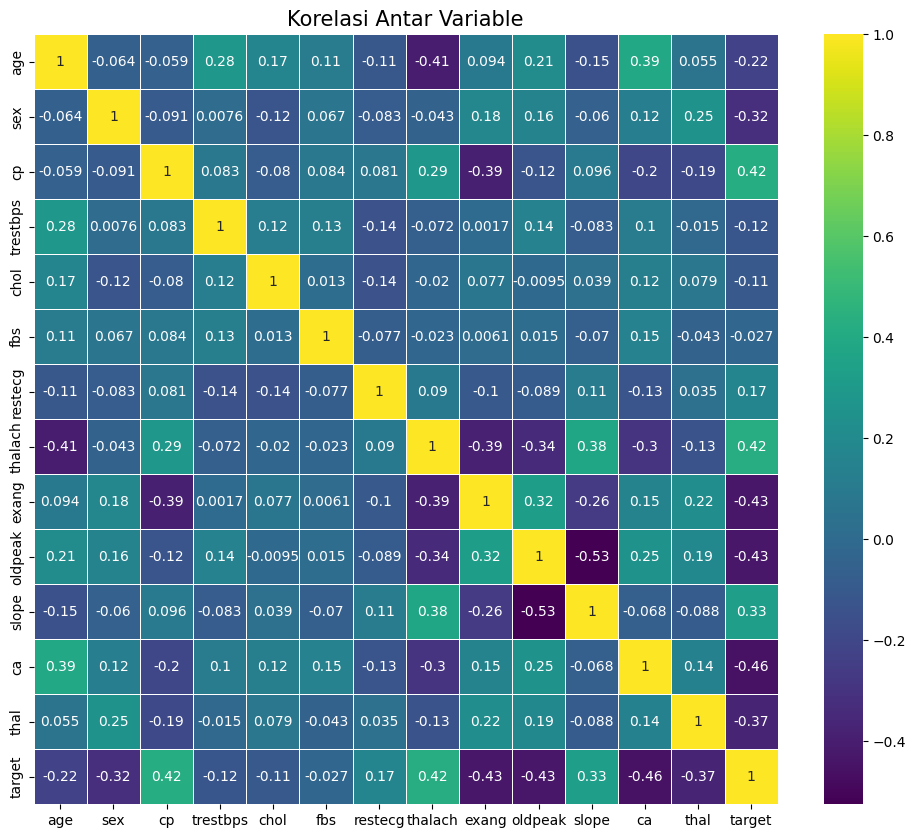

In [38]:
# melihat korelasi antar variable untuk mencari feature yang penting
plt.figure(figsize=(12,10))
cor = df.corr()
sns.heatmap(cor,annot=True, linewidth=.5, cmap="viridis")
plt.title('Korelasi Antar Variable', fontsize = 15)
plt.show()

In [39]:
cor_matrix = df.corr()
cor_matrix

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.064118,-0.058687,0.282669,0.171015,0.106885,-0.110517,-0.411108,0.093718,0.209254,-0.149095,0.392130,0.054752,-0.222416
sex,-0.064118,1.000000,-0.091357,0.007572,-0.123863,0.066692,-0.083290,-0.042981,0.182596,0.157352,-0.060014,0.122489,0.245682,-0.318896
cp,-0.058687,-0.091357,1.000000,0.083242,-0.080369,0.084389,0.080836,0.285605,-0.388610,-0.122582,0.095881,-0.202923,-0.188487,0.416319
trestbps,0.282669,0.007572,0.083242,1.000000,0.115138,0.127221,-0.139228,-0.071600,0.001726,0.144438,-0.083024,0.101059,-0.014615,-0.115614
chol,0.171015,-0.123863,-0.080369,0.115138,1.000000,0.013066,-0.142285,-0.020128,0.076547,-0.009534,0.039352,0.124800,0.078868,-0.105627
fbs,0.106885,0.066692,0.084389,0.127221,0.013066,1.000000,-0.077417,-0.023484,0.006080,0.015070,-0.069563,0.150552,-0.042766,-0.027210
restecg,-0.110517,-0.083290,0.080836,-0.139228,-0.142285,-0.077417,1.000000,0.089556,-0.104440,-0.089255,0.111841,-0.126825,0.035452,0.171453
thalach,-0.411108,-0.042981,0.285605,-0.071600,-0.020128,-0.023484,0.089556,1.000000,-0.387726,-0.341190,0.376494,-0.296480,-0.134498,0.422559
exang,0.093718,0.182596,-0.388610,0.001726,0.076547,0.006080,-0.104440,-0.387726,1.000000,0.318620,-0.259780,0.154768,0.223241,-0.431599
oldpeak,0.209254,0.157352,-0.122582,0.144438,-0.009534,0.015070,-0.089255,-0.341190,0.318620,1.000000,-0.525142,0.245318,0.189228,-0.434108


In [40]:
#Mengurutkan korelasi
cor_matrix['target'].sort_values()

ca         -0.456989
oldpeak    -0.434108
exang      -0.431599
thal       -0.370759
sex        -0.318896
age        -0.222416
trestbps   -0.115614
chol       -0.105627
fbs        -0.027210
restecg     0.171453
slope       0.326473
cp          0.416319
thalach     0.422559
target      1.000000
Name: target, dtype: float64

In [41]:
# Variabel terpilih
df = df[['cp', 'thalach', 'slope', 'oldpeak', 'exang', 'ca', 'thal', 'sex', 'age', 'target']]